In [8]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns


plt.style.use("default")
sns.set_theme(context="notebook", style="whitegrid")

In [9]:
PATH = "../../statsbomb_pipeline/data/processed/team/team_season.csv"
df = pd.read_csv(PATH)
df.head(10)
print("Dtypes:\n", df.dtypes, "\n")
print("Missing values:\n", df.isna().sum())

Dtypes:
 team_id                   int64
team_name                object
matches_played            int64
wins                      int64
draws                     int64
losses                    int64
goals_for                 int64
goals_against             int64
shots_for                 int64
passes_for                int64
carries_for               int64
ppa_for                   int64
f3_entries_for            int64
xg_for                  float64
xthreat_for             float64
goal_diff                 int64
xg_per_match            float64
xthreat_per_match       float64
goals_per_match         float64
ppa_per_match           float64
f3_entries_per_match    float64
dtype: object 

Missing values:
 team_id                 0
team_name               0
matches_played          0
wins                    0
draws                   0
losses                  0
goals_for               0
goals_against           0
shots_for               0
passes_for              0
carries_for             0


In [10]:
# Target variables for this analysis
target_cols = [
    "xg_for",
    "xg_per_match",
    "goals_per_match",
    "wins",
]

# Columns that are identifiers / not useful as features
id_cols = [
    "team_id",
    "team_name",
    "season",
    "competition",
    "matches_played",
    # add or remove as needed based on your actual columns
]

# All numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Candidate feature columns = numeric, not targets, not ids
feature_cols = [
    col for col in numeric_cols
    if col not in target_cols and col not in id_cols
]

print("Targets:", target_cols)
print("Num features:", len(feature_cols))
print("Sample feature columns:", feature_cols[:10])


Targets: ['xg_for', 'xg_per_match', 'goals_per_match', 'wins']
Num features: 14
Sample feature columns: ['draws', 'losses', 'goals_for', 'goals_against', 'shots_for', 'passes_for', 'carries_for', 'ppa_for', 'f3_entries_for', 'xthreat_for']


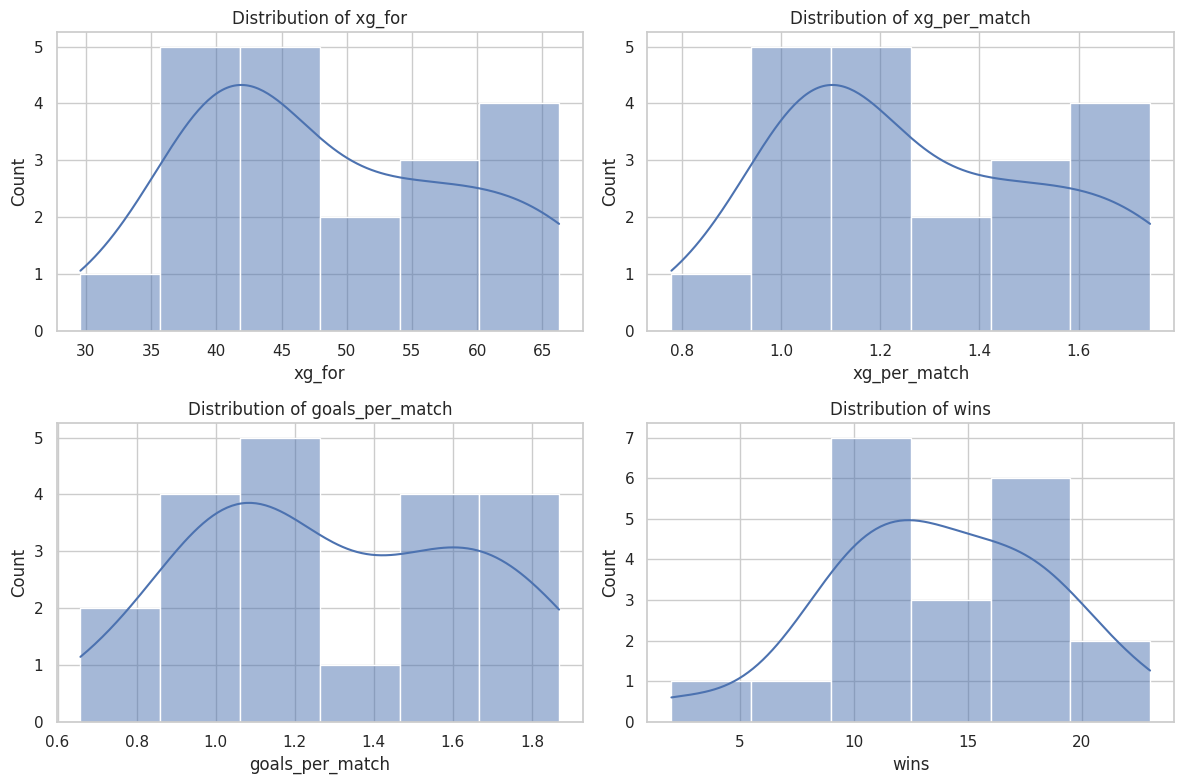

In [11]:
# Histograms for targets
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, target_cols):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()


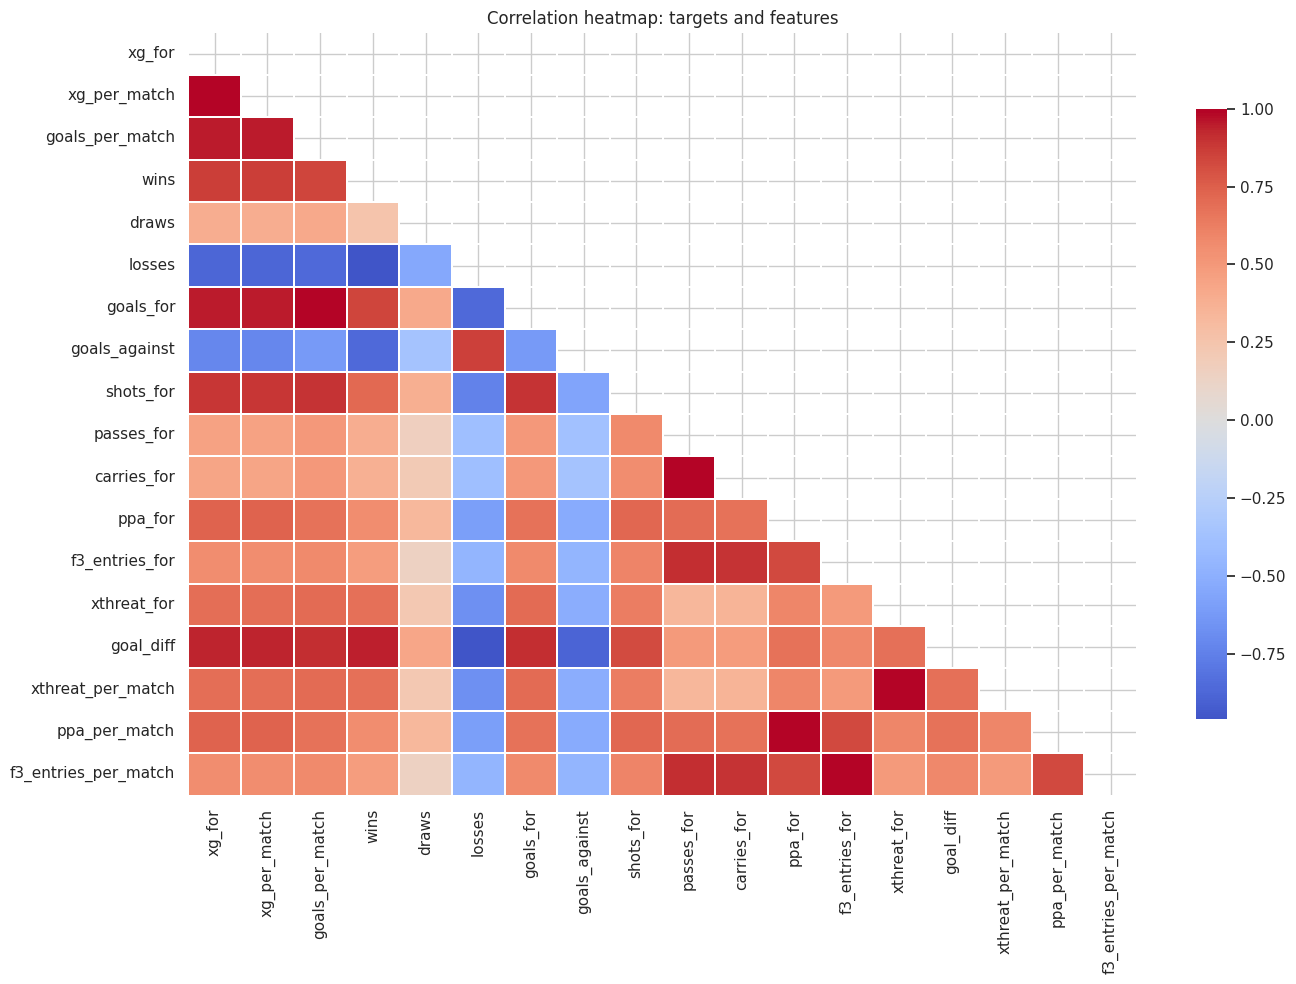

In [13]:
# Choose a subset for the heatmap to keep it readable
corr_cols = target_cols + feature_cols  # you can slice feature_cols if too many

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    annot=False,
    center=0,
    linewidths=0.3,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation heatmap: targets and features")
plt.tight_layout()
plt.show()


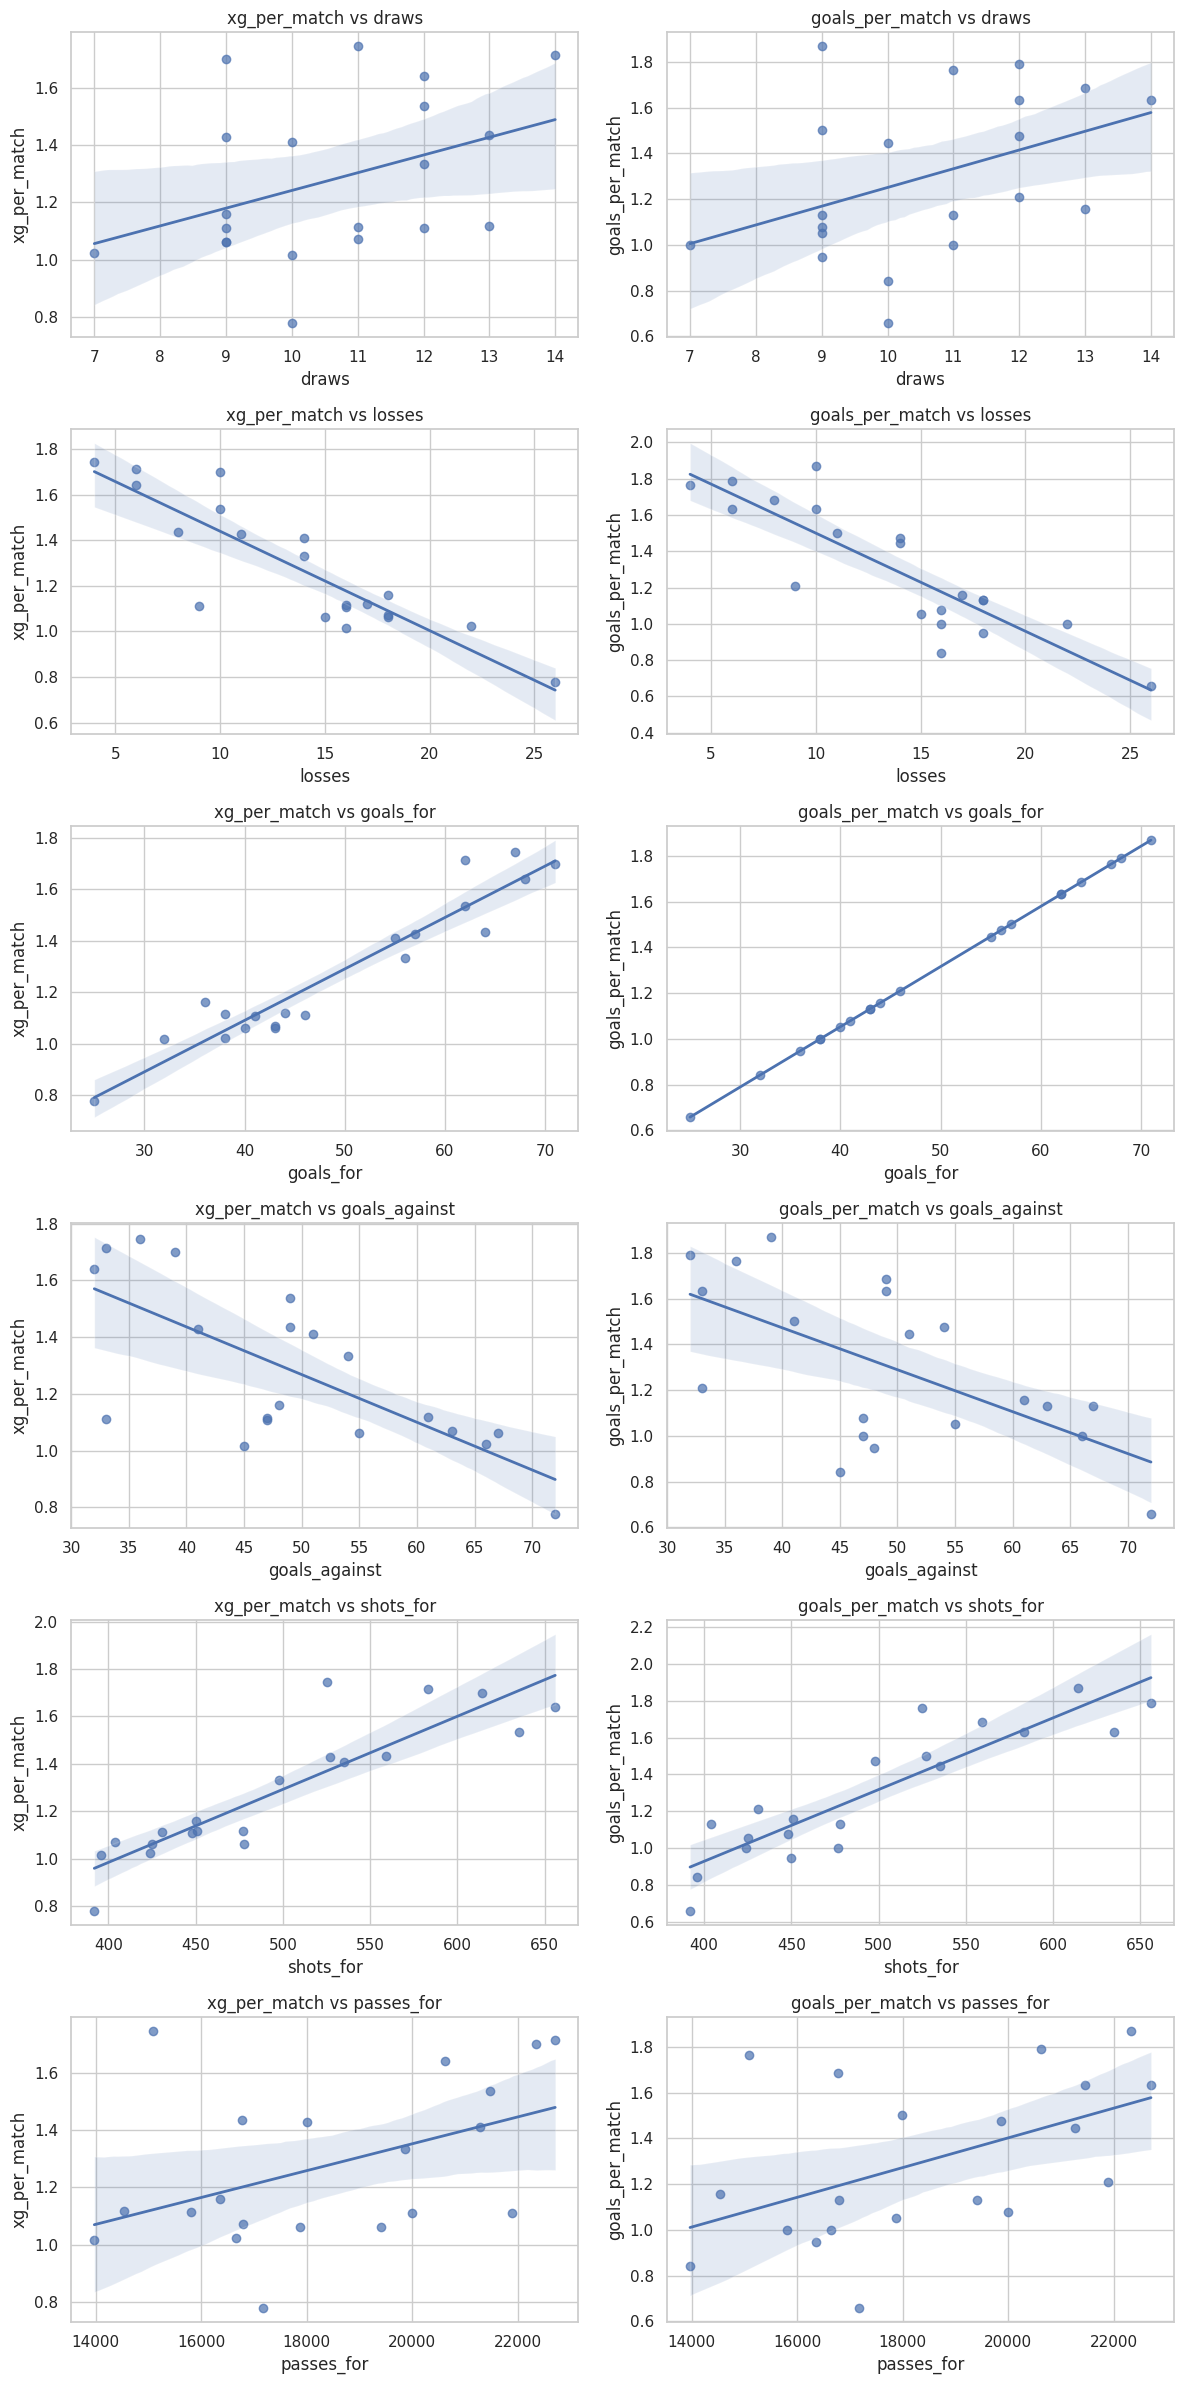

In [14]:
# Pick a few features you care about for first pass
features_to_plot = feature_cols[:6]  # or hand-pick once you inspect them
targets_to_plot = ["xg_per_match", "goals_per_match"]  # focus on per-match outputs

n_features = len(features_to_plot)
n_targets = len(targets_to_plot)

fig, axes = plt.subplots(
    n_features,
    n_targets,
    figsize=(6 * n_targets, 4 * n_features),
    sharex=False,
    sharey=False
)

if n_features == 1 and n_targets == 1:
    axes = np.array([[axes]])
elif n_features == 1 or n_targets == 1:
    axes = np.atleast_2d(axes)

for i, feat in enumerate(features_to_plot):
    for j, targ in enumerate(targets_to_plot):
        ax = axes[i, j]
        sns.regplot(
            data=df,
            x=feat,
            y=targ,
            scatter_kws={"alpha": 0.7},
            line_kws={"linewidth": 2},
            ax=ax,
        )
        ax.set_xlabel(feat)
        ax.set_ylabel(targ)
        ax.set_title(f"{targ} vs {feat}")

plt.tight_layout()
plt.show()
